In [1]:


# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load in 

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the "../input/" directory.
# For example, running this (by clicking run or pressing Shift+Enter) will list the files in the input directory
# from subprocess import check_output
# print(check_output(["ls", "../input"]).decode("utf8"))

# Any results you write to the current directory are saved as output.

In [2]:
# Importing packages

import os
import pandas as pd
from pandas import DataFrame,Series
from sklearn import tree
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
# import statsmodels.formula.api as smf
# import statsmodels.api as sm
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
from sklearn import neighbors
from sklearn import linear_model
from sklearn.preprocessing import normalize
from xgboost import XGBRegressor
import torch
import torch.nn as nn
import torch.optim as optim


In [3]:
system='/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv'
f = pd.read_csv(f"{system}", delimiter='\t')

def preprocess_data(df):
    # Identify the target column dynamically
    target_column = None
    for col in df.columns:

        if 'gibbs energy' in col.lower() or 'gibbs_energy' in col.lower():  # Adjust the keyword as needed
            target_column = col
            break
    
    if target_column is None:
        raise ValueError("No target column containing 'gibbs_energy' found.")
    
    # Extract the target variable
    y = df[target_column]
    
    # Drop the target column from features
    X = df.drop(columns=[target_column])
    
    # Encode quantitative variables
    for col in X.columns:

        if not pd.api.types.is_numeric_dtype(X[col]):
            
            # Assign integer values ranging from 0 to n-1
            X[col] = X[col].astype('category').cat.codes
    
    
    return X, y


X, y = preprocess_data(f)

In [4]:
X

,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
0,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1000,4
1,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1010,4
2,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1020,4
3,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1030,4
4,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1040,4
...,...,...,...,...,...,...,...,...,...
8176,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1760,1
8177,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1770,1
8178,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1780,1
8179,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1790,1


In [5]:
import pandas as pd

# Example y_true values (original scale)
# data = {
#     'y_true': [50, 55, 60, 65, 70]
# }
# df = pd.DataFrame(data)

# Compute the mean and standard deviation of the original y values
u = y.mean()
s = y.std()

# RMSE in the standardized scale
rmse_standardized = 0.027313798387834844  # Example standardized RMSE

# Convert RMSE to the original scale
rmse_original = rmse_standardized * s

print(f"RMSE in the original scale: {rmse_original:.4f}")


RMSE in the original scale: 620.7425


/tmp/ipykernel_251487/4252257973.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


KeyError: 'Gibbs_energy_FCC_A1'

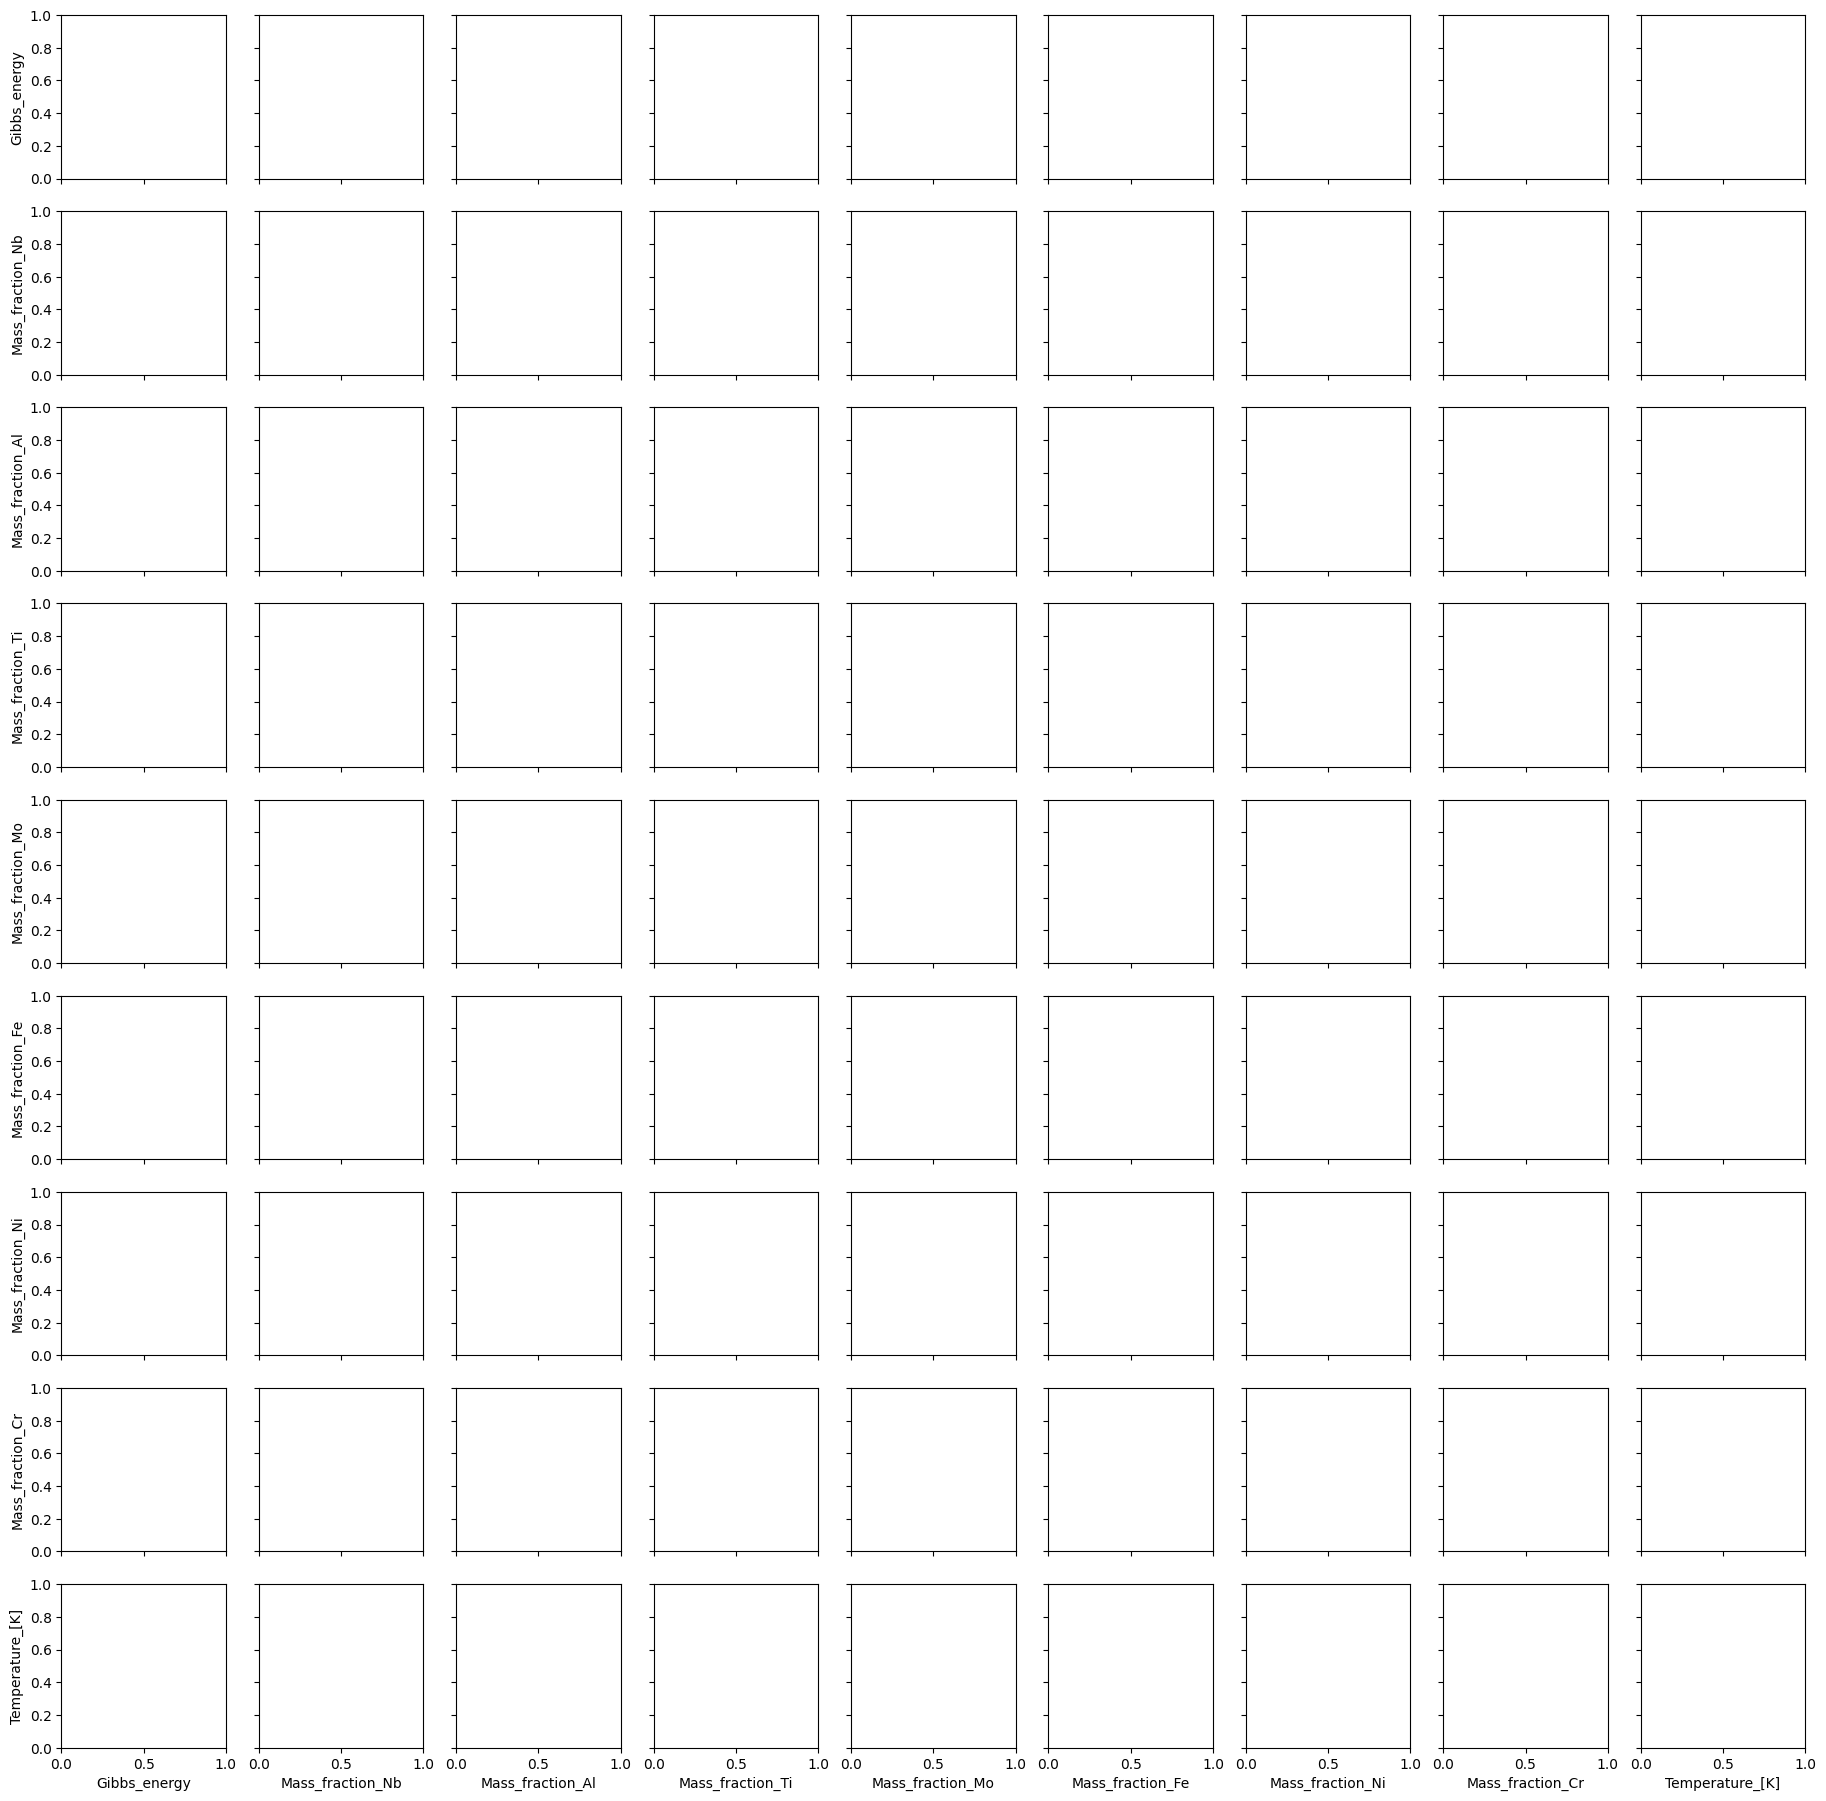

In [6]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
file_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv'

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")

# print(df)

# Plot pairwise relationships
sns.pairplot(df, hue='Gibbs_energy_FCC_A1')  # Replace 'target_column' with the actual name
plt.show()


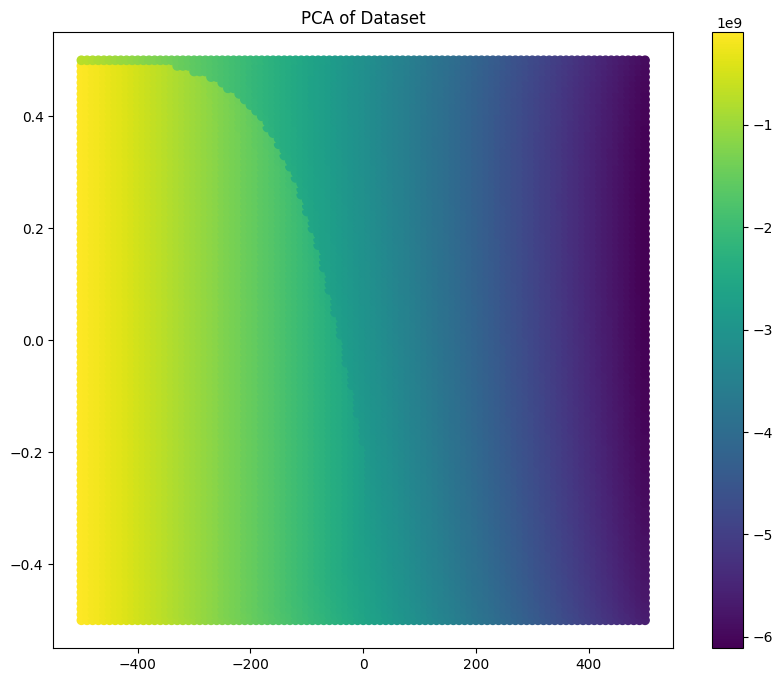

KeyboardInterrupt: 

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Load data
X = df.drop(columns=['Gibbs_energy'])  # Features
y = df['Gibbs_energy']  # Target

# Apply PCA
pca = PCA(n_components=2)
pca_result = pca.fit_transform(X)

plt.figure(figsize=(10, 8))
plt.scatter(pca_result[:, 0], pca_result[:, 1], c=y, cmap='viridis')
plt.colorbar()
plt.title('PCA of Dataset')
plt.show()

# Apply t-SNE
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(X)

plt.figure(figsize=(10, 8))
plt.scatter(tsne_result[:, 0], tsne_result[:, 1], c=y, cmap='viridis')
plt.colorbar()
plt.title('t-SNE of Dataset')
plt.show()

# PCA creates 2 matrices:

# PCA.


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage

# Load data
X = df.drop(columns=['Gibbs_energy'])

# Perform hierarchical clustering
Z = linkage(X, method='ward')

# Plot dendrogram
plt.figure(figsize=(12, 8))
dendrogram(Z)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()


KeyboardInterrupt: 

/home/couchbucks/Documents/saketh/regression/env/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)
/home/couchbucks/Documents/saketh/regression/env/lib/python3.10/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


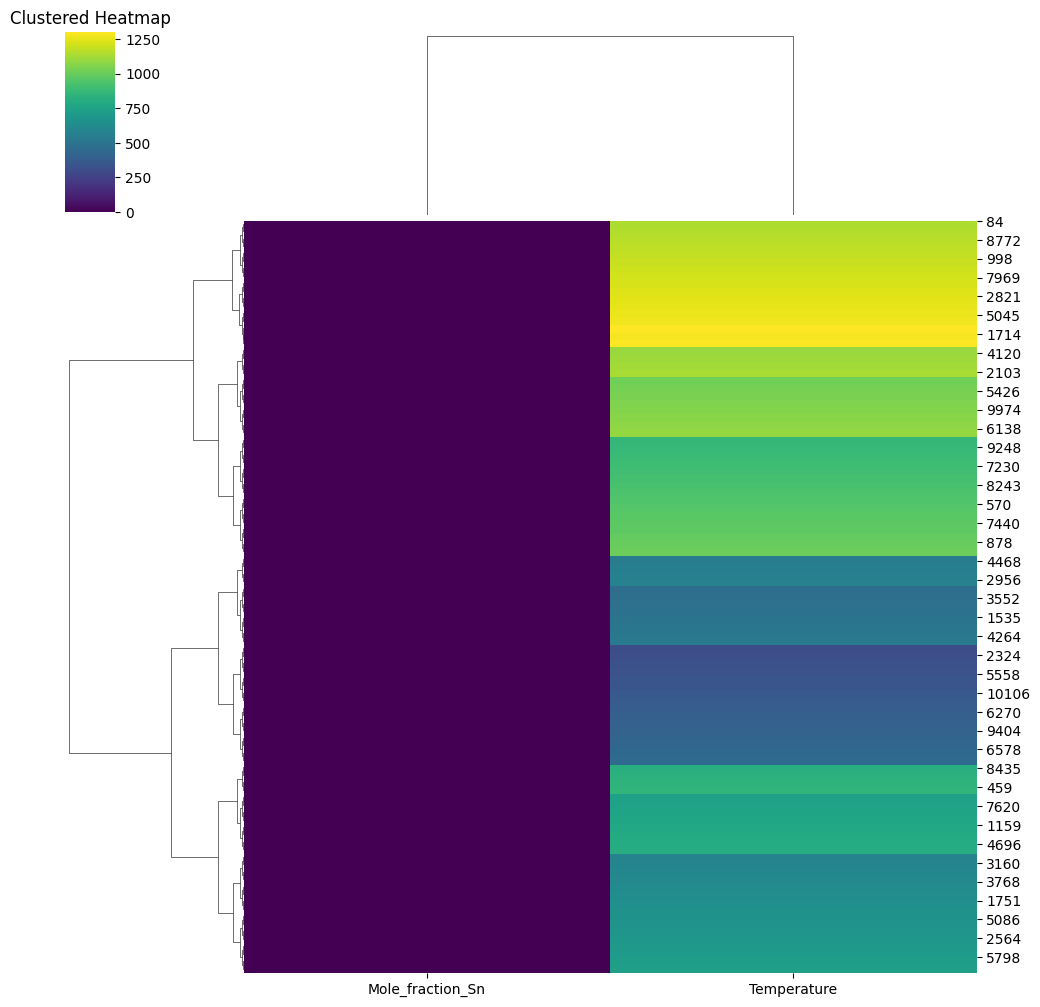

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
X = df.drop(columns=['Gibbs_energy'])

# Create a clustered heatmap
sns.clustermap(X, method='ward', cmap='viridis', figsize=(10, 10))
plt.title('Clustered Heatmap')
plt.show()


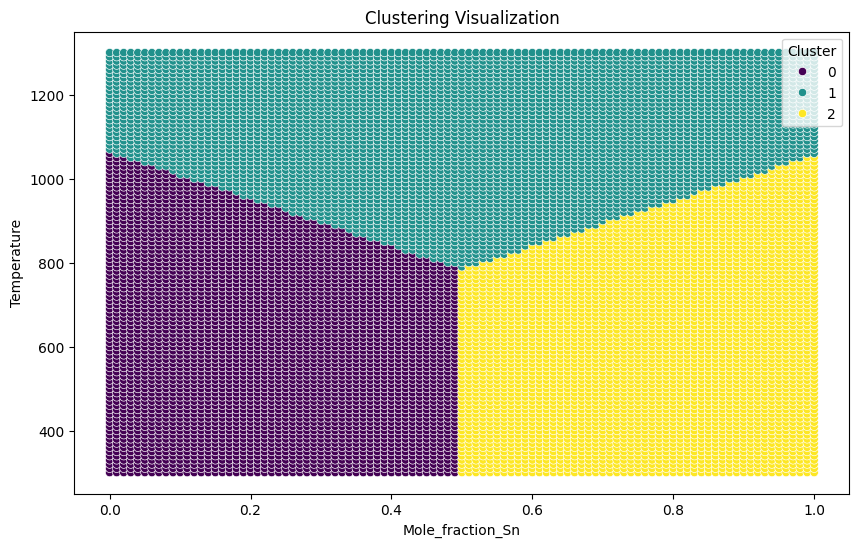

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Prepare the features (Mole_fraction_Sn and Temperature)
X = df[['Mole_fraction_Sn', 'Temperature']]

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3)  # Choose the number of clusters (k) based on your data
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Visualize the clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(x='Mole_fraction_Sn', y='Temperature', hue='Cluster', data=df, palette='viridis')
plt.title('Clustering Visualization')
plt.xlabel('Mole_fraction_Sn')
plt.ylabel('Temperature')
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Set random seed for reproducibility
np.random.seed(42)

# Number of samples
n_samples = 300

# Generate overlapping clusters
feature1 = np.concatenate([
    np.random.normal(loc=0.0, scale=1.0, size=n_samples // 3),
    np.random.normal(loc=3.0, scale=1.5, size=n_samples // 3),
    np.random.normal(loc=6.0, scale=1.0, size=n_samples // 3)
])
feature2 = np.concatenate([
    np.random.normal(loc=0.0, scale=1.0, size=n_samples // 3),
    np.random.normal(loc=3.0, scale=1.5, size=n_samples // 3),
    np.random.normal(loc=6.0, scale=1.0, size=n_samples // 3)
])

# Create a DataFrame
data = pd.DataFrame({
    'Feature1': feature1,
    'Feature2': feature2
})

# Save to CSV
data.to_csv('overlapping_clusters.csv', index=False)

# Print the first few rows
print(data.head())


   Feature1  Feature2
0  0.496714 -0.828995
1 -0.138264 -0.560181
2  0.647689  0.747294
3  1.523030  0.610370
4 -0.234153 -0.020902


   Feature1  Feature2  Cluster
0  0.496714 -0.828995        2
1 -0.138264 -0.560181        2
2  0.647689  0.747294        2
3  1.523030  0.610370        2
4 -0.234153 -0.020902        2


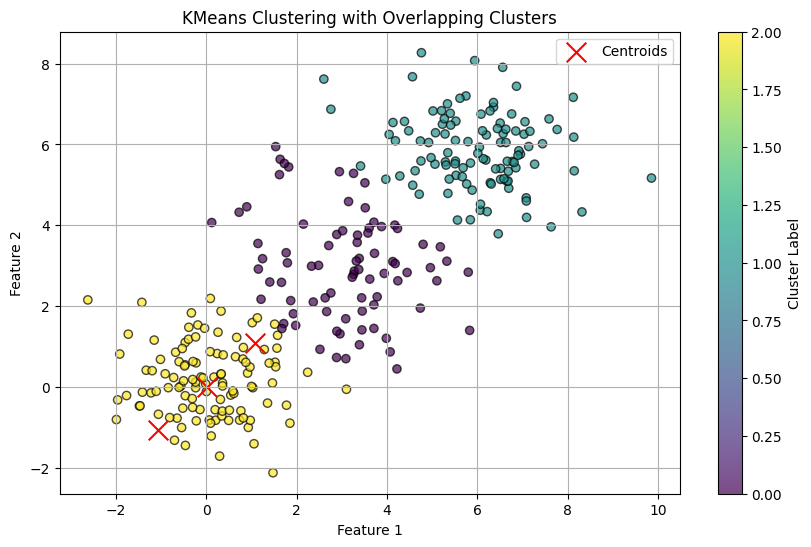

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Set random seed for reproducibility
np.random.seed(42)

# Number of samples
n_samples = 300

# Generate overlapping clusters
feature1 = np.concatenate([
    np.random.normal(loc=0.0, scale=1.0, size=n_samples // 3),
    np.random.normal(loc=3.0, scale=1.5, size=n_samples // 3),
    np.random.normal(loc=6.0, scale=1.0, size=n_samples // 3)
])
feature2 = np.concatenate([
    np.random.normal(loc=0.0, scale=1.0, size=n_samples // 3),
    np.random.normal(loc=3.0, scale=1.5, size=n_samples // 3),
    np.random.normal(loc=6.0, scale=1.0, size=n_samples // 3)
])

# Create a DataFrame
data = pd.DataFrame({
    'Feature1': feature1,
    'Feature2': feature2
})

# Scale the data
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(data_scaled)

# Add cluster labels to DataFrame
data['Cluster'] = clusters

# Save to CSV
data.to_csv('overlapping_clusters_with_labels.csv', index=False)

# Print the first few rows
print(data.head())

# Visualization
plt.figure(figsize=(10, 6))
scatter = plt.scatter(data['Feature1'], data['Feature2'], c=data['Cluster'], cmap='viridis', marker='o', edgecolor='k', alpha=0.7)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, c='red', marker='x', label='Centroids')
plt.title('KMeans Clustering with Overlapping Clusters')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.colorbar(scatter, label='Cluster Label')
plt.grid(True)
plt.show()


In [ ]:
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.cm as cm

# Assuming the data has been clustered with KMeans or another clustering algorithm
cluster_labels = ...  # replace with your clustering labels
silhouette_avg = silhouette_score(X, cluster_labels)
sample_silhouette_values = silhouette_samples(X, cluster_labels)

y_lower = 10
n_clusters = len(set(cluster_labels))
fig, ax1 = plt.subplots(1, 1)
ax1.set_xlim([-0.1, 1])
ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

for i in range(n_clusters):
    ith_cluster_silhouette_values = sample_silhouette_values[cluster_labels == i]
    ith_cluster_silhouette_values.sort()
    size_cluster_i = ith_cluster_silhouette_values.shape[0]
    y_upper = y_lower + size_cluster_i
    color = cm.nipy_spectral(float(i) / n_clusters)
    ax1.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_silhouette_values,
                      facecolor=color, edgecolor=color, alpha=0.7)
    ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

ax1.set_title("Silhouette plot")
ax1.set_xlabel("Silhouette coefficient values")
ax1.set_ylabel("Cluster label")
ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
plt.show()


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load data
file_path = '/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv'

if file_path.endswith('.xlsx'):
    df = pd.read_excel(file_path)
elif file_path.endswith('.txt') or file_path.endswith('.csv'):
    df = pd.read_csv(file_path, delim_whitespace=True)
else:
    print("Unsupported file format. Please use .txt or .xlsx files.")



/tmp/ipykernel_32116/1480857581.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [ ]:
df.iloc[[1256]]

,Gibbs_energy,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
1256,-91141.77,0.15,0.005,0.01,0.03,0.195,0.53,0.18,1410,nb


In [ ]:
df_nb = df[df['temp_class']=='nb']
df_nb.head()

,Gibbs_energy,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
0,-49238.12,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1000,nb
1,-50066.89,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1010,nb
2,-50898.83,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1020,nb
3,-51733.93,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1030,nb
4,-52572.17,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1040,nb


In [ ]:
for col in df.columns:

    if not pd.api.types.is_numeric_dtype(df[col]):
        # Assign integer values ranging from 0 to n-1
        df[col] = df[col].astype('category').cat.codes

In [ ]:
df.head()

,Gibbs_energy,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
0,-49238.12,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1000,4
1,-50066.89,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1010,4
2,-50898.83,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1020,4
3,-51733.93,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1030,4
4,-52572.17,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1040,4


In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# SCALER_DISPATCH is a dictionary mapping scaler names to their respective classes
SCALER_DISPATCH = {
    'standard': StandardScaler,
    'minmax': MinMaxScaler
    # Add other scalers as needed
}

def preprocess_and_scale(df, target_column, data_scaler='standard'):
    # Separate the target and features
    y = df[target_column]
    X = df.drop(columns=[target_column])
    
    # Convert categorical features to numerical codes
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = X[col].astype('category').cat.codes
    
    # Convert DataFrame to numpy array
    X = X.values
    y = y.values
    
    # Apply scaling if a scaler is specified
    if data_scaler in SCALER_DISPATCH:
        scaler = SCALER_DISPATCH[data_scaler]()
        
        # Scale X
        X = scaler.fit_transform(X)
        
        # Scale y (reshaping it to 2D, then flattening back to 1D)
        y_2d = np.reshape(y, (y.shape[0], 1))
        y = scaler.fit_transform(y_2d).flatten()

    return X, y

In [ ]:
# X, y = preprocess_and_scale(df, target_column='Gibbs_energy', data_scaler='standard')

target_column = 'Gibbs_energy'
y = df[target_column]
X = df.drop(columns=[target_column])

# Optionally convert categorical values to numerical
# This step is redundant in this case as all are numeric, but useful if there are categorical variables.
for col in X.columns:
    if not pd.api.types.is_numeric_dtype(X[col]):
        X[col] = X[col].astype('category').cat.codes

# Apply Standard Scaler if needed
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
y_scaled = scaler.fit_transform(y.values.reshape(-1, 1)).flatten()

# # Combine X and y back together into a DataFrame
# combined_df = pd.DataFrame(X_scaled, columns=X.columns)
# combined_df[target_column] = y_scaled

In [ ]:
X_scaled

array([[-1.37972892, -0.28569887, -0.40870239, ..., -0.17921157,
        -1.71079785,  0.60632451],
       [-1.37972892, -0.28569887, -0.40870239, ..., -0.17921157,
        -1.6680279 ,  0.60632451],
       [-1.37972892, -0.28569887, -0.40870239, ..., -0.17921157,
        -1.62525795,  0.60632451],
       ...,
       [-0.38435306, -0.28569887, -0.40870239, ...,  5.57999674,
         1.62525795, -1.24939595],
       [-0.38435306, -0.28569887, -0.40870239, ...,  5.57999674,
         1.6680279 , -1.24939595],
       [-0.38435306, -0.28569887, -0.40870239, ...,  5.57999674,
         1.71079785, -1.24939595]])

In [ ]:
import feyn

ql = feyn.QLattice()

This version of Feyn and the QLattice is available for academic, personal, and non-commercial use. By using the community version of this software you agree to the terms and conditions which can be found at https://abzu.ai/eula.

In [ ]:
from feyn.datasets import make_regression

train, test = make_regression()

In [ ]:
type(train)

pandas.core.frame.DataFrame

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
                        X, 
                        y, 
                        test_size=.2,  
                        random_state=0  # Seed for reproducibility, changes each split
                    )

In [ ]:
train = pd.concat([x_train, y_train], axis=1)

In [ ]:
test = pd.concat([x_test, y_test], axis=1)

In [ ]:
test

,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class,Gibbs_energy
5522,0.05,0.005,0.01,0.10,0.195,0.53,0.18,1140,3,-63334.79
4871,0.05,0.005,0.01,0.02,0.195,0.53,0.18,1110,3,-60837.04
49,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1490,4,-93290.08
2526,0.05,0.100,0.01,0.03,0.195,0.53,0.18,1150,0,-80350.06
1060,0.13,0.005,0.01,0.03,0.195,0.53,0.18,1070,4,-59879.86
...,...,...,...,...,...,...,...,...,...,...
6040,0.05,0.005,0.01,0.16,0.195,0.53,0.18,1460,3,-92575.51
4392,0.05,0.005,0.17,0.03,0.195,0.53,0.18,1180,5,-77493.84
6825,0.05,0.005,0.01,0.03,0.200,0.53,0.18,1210,2,-69690.72
4986,0.05,0.005,0.01,0.03,0.195,0.53,0.18,1450,3,-91932.75


In [ ]:
# Extract the column names except for 'Gibbs_energy'
columns = train.columns.tolist()

columns.remove('Gibbs_energy')

# Create a dictionary for renaming
rename_dict = {col: f'x{i}' for i, col in enumerate(columns)}
rename_dict['Gibbs_energy'] = 'y'

# Rename the columns
df_renamed = df.rename(columns=rename_dict)

# Print the renamed DataFrame
print(df_renamed)

for original, new in rename_dict.items():
    print(f"{original} -> {new}")


              y    x0     x1    x2    x3     x4    x5    x6    x7  x8
0     -49238.12  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1000   4
1     -50066.89  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1010   4
2     -50898.83  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1020   4
3     -51733.93  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1030   4
4     -52572.17  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1040   4
...         ...   ...    ...   ...   ...    ...   ...   ...   ...  ..
8176 -121687.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1760   1
8177 -122729.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1770   1
8178 -123773.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1780   1
8179 -124819.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1790   1
8180 -125868.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1800   1

[8181 rows x 10 columns]
Mass_fraction_Nb -> x0
Mass_fraction_Al -> x1
Mass_fraction_Ti -> x2
Mass_fraction_Mo -> x3
Mass_fraction_Fe -> x4
Mass_fraction_Ni ->

In [ ]:
train=df_renamed

In [ ]:
train

,y,x0,x1,x2,x3,x4,x5,x6,x7,x8
0,-49238.12,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1000,4
1,-50066.89,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1010,4
2,-50898.83,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1020,4
3,-51733.93,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1030,4
4,-52572.17,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1040,4
...,...,...,...,...,...,...,...,...,...,...
8176,-121687.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1760,1
8177,-122729.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1770,1
8178,-123773.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1780,1
8179,-124819.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1790,1


In [ ]:
from feyn.datasets import make_regression

train, test = make_regression()

In [ ]:
train

,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x11,x12,x13,x14,x15,x16,x17,x18,x19,y
91,-1.660322,0.606888,1.823617,-0.242797,-1.348773,2.144247,-0.171862,-0.436320,-0.481108,1.653260,...,1.000265,0.599387,2.353347,1.368622,-0.788940,0.043147,1.729288,-0.231493,0.028262,-12.165537
58,-0.305239,1.333594,0.970637,0.114159,0.096634,-0.490462,-0.306805,0.487287,-0.451358,-0.857547,...,-0.172725,-0.804965,-1.181385,-2.624552,-1.488358,1.145609,0.268443,-0.987324,-1.118816,106.869569
65,1.764755,0.323772,-0.509045,-0.294959,-2.361317,0.595278,-1.376154,-1.795115,-0.686210,-0.598850,...,-0.250582,-0.632914,-1.065538,-0.941891,1.240500,1.289779,1.929560,0.477592,-0.278711,-183.273066
37,-0.737094,-0.832624,-0.630995,-0.689563,-2.163672,-0.356114,1.220915,-1.705647,0.925710,0.361437,...,-0.648909,-1.076323,1.422849,-0.311454,0.763507,0.706503,-0.132414,2.459186,0.501121,-267.460354
79,0.579067,2.244071,0.203214,-0.209050,1.963641,0.832428,0.726303,-0.690756,-0.663078,-0.870510,...,-0.776241,0.893306,-1.261226,2.502857,1.363307,0.077721,1.824409,0.253422,-0.330800,213.476701
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
60,0.756787,1.477614,-0.087029,-1.174306,0.969253,0.967140,-0.658244,-0.292779,0.216542,0.659412,...,-0.270469,1.386264,0.448792,0.146603,0.459283,-0.630501,0.268506,1.482211,0.021236,161.813327
23,1.824647,-0.543191,-0.024525,-0.468329,-2.833331,-0.407013,0.128114,-0.597845,0.616765,0.955925,...,-0.540723,1.021458,0.026825,-0.341194,-0.321977,1.280049,1.580352,-0.421232,0.312332,-16.235982
41,-0.606544,0.299396,-1.400541,1.139064,0.866063,2.577098,0.286569,1.632103,-0.814633,0.465298,...,-1.178310,0.284601,1.583966,-0.100265,0.670984,0.358884,0.624321,0.002084,-1.366702,97.565249
28,-0.506308,-0.587903,2.235013,0.420258,1.924538,-0.798391,0.867330,-0.788432,0.298820,0.701420,...,0.373971,1.204953,0.718518,0.044050,0.172658,-0.014292,0.487043,0.863261,-1.477427,142.349100


In [ ]:
models = ql.auto_run(train, output_name = 'y', n_epochs=30, max_complexity=50)

[INFO: feyn.tools._data._types] - Column 'x5' is constant (contains only one value) and will be skipped.


In [ ]:
vars(ql.auto_run)

{'__wrapped__': <function feyn._qlattice.QLattice.auto_run(self, data: pandas.core.frame.DataFrame, output_name: str, kind: str = 'auto', stypes: Optional[Dict[str, str]] = None, n_epochs: int = 10, threads: Union[int, str] = 'auto', max_complexity: int = 10, query_string: Optional[str] = None, loss_function: Optional[str] = None, criterion: Optional[str] = 'bic', sample_weights: Optional[Iterable[float]] = None, function_names: Optional[List[str]] = None, starting_models: Optional[List[feyn._model.Model]] = None) -> 'IPython cell'>}

In [ ]:
# Extract the column names except for 'Gibbs_energy'
columns = test.columns.tolist()

columns.remove('Gibbs_energy')

# Create a dictionary for renaming
rename_dict = {col: f'x{i}' for i, col in enumerate(columns)}
rename_dict['Gibbs_energy'] = 'y'

# Rename the columns
test = df.rename(columns=rename_dict)

# Print the renamed DataFrame
print(test)

for original, new in test.items():
    print(f"{original} -> {new}")


              y    x0     x1    x2    x3     x4    x5    x6    x7  x8
0     -49238.12  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1000   4
1     -50066.89  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1010   4
2     -50898.83  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1020   4
3     -51733.93  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1030   4
4     -52572.17  0.00  0.005  0.01  0.03  0.195  0.53  0.18  1040   4
...         ...   ...    ...   ...   ...    ...   ...   ...   ...  ..
8176 -121687.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1760   1
8177 -122729.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1770   1
8178 -123773.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1780   1
8179 -124819.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1790   1
8180 -125868.00  0.05  0.005  0.01  0.03  0.195  0.53  0.25  1800   1

[8181 rows x 10 columns]
y -> 0       -49238.12
1       -50066.89
2       -50898.83
3       -51733.93
4       -52572.17
          ...    
8176   -121687.00
817

In [ ]:
test

,y,x0,x1,x2,x3,x4,x5,x6,x7,x8
0,-49238.12,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1000,4
1,-50066.89,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1010,4
2,-50898.83,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1020,4
3,-51733.93,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1030,4
4,-52572.17,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1040,4
...,...,...,...,...,...,...,...,...,...,...
8176,-121687.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1760,1
8177,-122729.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1770,1
8178,-123773.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1780,1
8179,-124819.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1790,1


In [ ]:
best = models[0]
y_pred = best.predict(test)
y_acc = test['y'].values

In [ ]:
best.get_parameters(name='x0')

,x0_3,x0_28
scale,8.000000,8.000000
scale_offset,0.069307,0.069307
w,0.137305,0.192240
bias,-2.048907,-0.168405
detect_scale,0.000000,0.000000


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
mean_absolute_error(y_acc, y_pred)

np.float64(238.2669219862728)

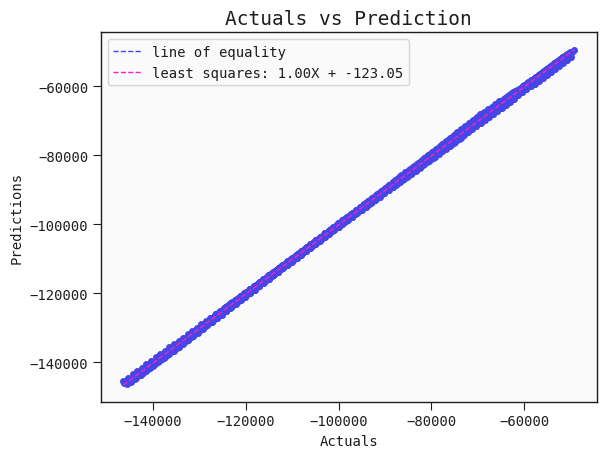

In [ ]:
best.plot(train, test)
best.plot_regression(test)

In [ ]:
import pickle

lr_model = pickle.load(open('/home/couchbucks/Documents/saketh/regression/regression/718_all/train_results/saved_models/Linear Regression/Linear Regression_1/Linear Regression_1.pkl', 'rb'))

In [ ]:
def preprocess_data(df):
    # Identify the target column dynamically
    target_column = None
    for col in df.columns:

        if 'gibbs energy' in col.lower() or 'gibbs_energy' in col.lower():  # Adjust the keyword as needed
            target_column = col
            break
    
    if target_column is None:
        raise ValueError("No target column containing 'gibbs_energy' found.")
    
    # Extract the target variable
    y = df[target_column]
    
    # Drop the target column from features
    X = df.drop(columns=[target_column])
    
    # Encode quantitative variables
    for col in X.columns:

        if not pd.api.types.is_numeric_dtype(X[col]):
            
            # Assign integer values ranging from 0 to n-1
            X[col] = X[col].astype('category').cat.codes
    
    
    return X, y

X, y = preprocess_data(combined_df)

In [ ]:
X = X.values
y = y.values

In [ ]:
lr_model.coef_

array([-5.39245521e-02, -2.00089551e-01, -1.36617167e-01,  1.03223485e-02,
       -9.02902447e-04,  0.00000000e+00,  1.34813620e-02, -9.71391353e-01,
        5.78643312e-03])

In [ ]:
y_pred = lr_model.predict(X)

In [ ]:
y.shape

(8181,)

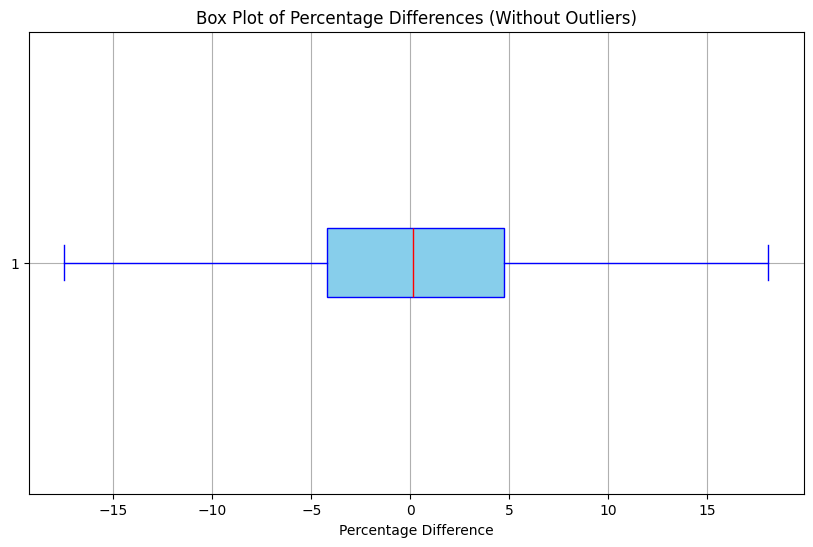

1266
Minimum percentage difference:
Index: 1256
True Gibbs Energy: -6.154854326541204e-05
Predicted Gibbs Energy: -0.0177532915482664
Percentage Difference: -28744.373248136773 %

Maximum percentage difference:
Index: 3843
True Gibbs Energy: 0.0006368030111016198
Predicted Gibbs Energy: 0.0323647878778428
Percentage Difference: 4982.3861246909355 %


NameError: name 'max_diff' is not defined

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# # Sample DataFrame as provided
# df = pd.DataFrame({
#     'Gibbs_energy': [-49238.12, -50066.89],
#     'Mass_fraction_Nb': [0.0, 0.0],
#     'Mass_fraction_Al': [0.005, 0.005],
#     'Mass_fraction_Ti': [0.01, 0.01],
#     'Mass_fraction_Mo': [0.03, 0.03],
#     'Mass_fraction_Fe': [0.195, 0.195],
#     'Mass_fraction_Ni': [0.53, 0.53],
#     'Mass_fraction_Cr': [0.18, 0.18],
#     'Temperature_[K]': [1000, 1010],
#     'temp_class': [4, 4]
# })

# Apply the formula to calculate predicted Gibbs energy
# combined_df['preds'] = (
#     -0.95847567096412 * combined_df['Temperature_[K]']
#     - np.sin(-0.23560148 * combined_df['Mass_fraction_Nb'] * np.sin(combined_df['Mass_fraction_Al'])
#              + 0.23560148 * combined_df['Mass_fraction_Al']
#              + 0.142045748453794 * combined_df['Mass_fraction_Ti'])
# )

combined_df['preds'] = y_pred


# print(combined_df)

combined_df['percentage_diff'] = 100 * np.abs(combined_df['Gibbs_energy'] - combined_df['preds']) / combined_df['Gibbs_energy']

perc_diff = list(combined_df['percentage_diff'])

# Plotting the box plot without outliers
plt.figure(figsize=(10, 6))
plt.boxplot(
    combined_df['percentage_diff'].dropna(), 
    vert=False, 
    patch_artist=True, 
    showfliers=False,  # Hide outliers
    boxprops=dict(facecolor='skyblue', color='blue'),
    whiskerprops=dict(color='blue'),
    capprops=dict(color='blue'),
    medianprops=dict(color='red')
)
plt.title("Box Plot of Percentage Differences (Without Outliers)")
plt.xlabel("Percentage Difference")
plt.grid(True)
plt.show()
# Find highest and lowest percentage differences
min_index = combined_df['percentage_diff'].idxmin()
max_index = combined_df['percentage_diff'].idxmax()


# Calculate Q1 (25th percentile) and Q3 (75th percentile)
Q1 = np.percentile(perc_diff, 25)
Q3 = np.percentile(perc_diff, 75)

# Calculate IQR (Interquartile Range)
IQR = Q3 - Q1

# Determine the bounds for outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Count outliers
outliers = [x for x in perc_diff if (x > upper_bound or x < lower_bound)]
num_outliers = len(outliers)

print(num_outliers)

# Get the corresponding rows for min and max percentage differences
min_row = combined_df.loc[min_index]
max_row = combined_df.loc[max_index]

# Print details for the minimum percentage difference
print("Minimum percentage difference:")
print("Index:", min_index)
print("True Gibbs Energy:", min_row['Gibbs_energy'])
print("Predicted Gibbs Energy:", min_row['preds'])
print("Percentage Difference:", min_row['percentage_diff'], "%")

# Print details for the maximum percentage difference
print("\nMaximum percentage difference:")
print("Index:", max_index)Dr. Bush Things To Talk About
print("True Gibbs Energy:", max_row['Gibbs_energy'])
print("Predicted Gibbs Energy:", max_row['preds'])
print("Percentage Difference:", max_row['percentage_diff'], "%")

print(f"Highest percentage difference: {max_diff:.2f}%")
print(f"Lowest percentage difference: {min_diff:.2f}%")

# Plotting true vs predicted Gibbs energy
ax = combined_df.plot(x="Gibbs_energy", y="preds", kind="scatter", color='blue', label='Prediction')
combined_df.plot(x="Gibbs_energy", y="Gibbs_energy", color="red", kind="scatter", ax=ax, label='Ground Truth')

# Add title and legend
plt.title("Prediction vs. True Values - Gibbs Energy")
plt.xlabel("True Gibbs Energy")
plt.ylabel("Predicted Gibbs Energy")
plt.legend()

# Show the plot
plt.show()


In [7]:
abs_perc_diff = [abs(x) for x in perc_diff]

NameError: name 'perc_diff' is not defined

In [ ]:
x_vals = [x for x in range(len(abs_perc_diff))]

Text(0, 0.5, 'Percentage Diff')

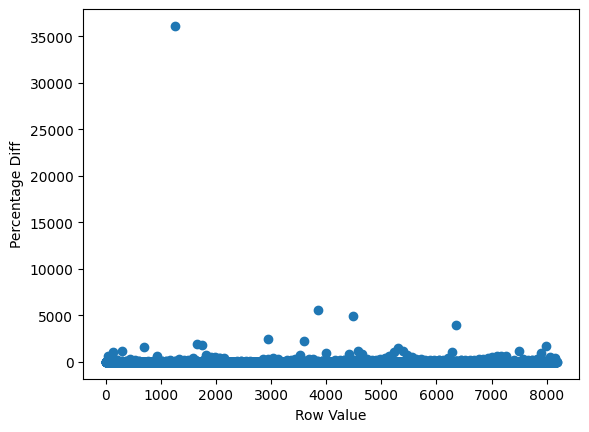

In [ ]:
plt.scatter(x_vals, abs_perc_diff)

# plt.title("Prediction vs. True Values - Gibbs Energy")
plt.xlabel("Row Value")
plt.ylabel("Percentage Diff")

In [ ]:
from dataclasses import dataclass, asdict
import yaml
from pathlib import Path
import os
from pysr import PySRRegressor
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from argparse import ArgumentParser
from sklearn.metrics import mean_squared_error, mean_absolute_error
# from training import RegressorsTrainingConfig
from sklearn.preprocessing import StandardScaler, MinMaxScaler

SCALER_DISPATCH = {
    'standard': StandardScaler,
    'min_max': MinMaxScaler
}

@dataclass
class SymbolicRegressionConfig():
    system_path: str = ''
    output_dir: str = ''
    niterations: int = 1000
    populations: int = 40
    procs: int = 4
    test_size: float = 0.2
    random_state: int = 42
    binary_operators: list = None
    unary_operators: list = None
    num_samples: int = 10  # Number of times to sample/split the data

    def __post_init__(self):
        if self.binary_operators is None:
            self.binary_operators = ["+", "*", "-", "/", 'max', 'min', 'mod', 'cond', 'greater', 'logical_or', "logical_and"]
        if self.unary_operators is None:
            self.unary_operators = ["cos", "sin", "exp", "log", "sqrt", 'neg', 'cube', 'abs', 'log10', 'tan', 'sinh', 'cosh', 'tanh', 'atan', 'asinh']

        Path(self.output_dir).mkdir(parents=True, exist_ok=True)

        with open(os.path.join(self.output_dir, "symbolic_regression_config.yaml"), "w") as fp:
            yaml.dump(asdict(self), fp)

def calculate_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    return mse, mae, rmse

def perform_symbolic_regression(X_train, y_train, config):
    model = PySRRegressor(
        niterations=config.niterations,
        binary_operators=config.binary_operators,
        unary_operators=config.unary_operators,
        populations=config.populations,
        procs=config.procs,
        batching=True,
        maxsize=60,
        maxdepth=15,
        parsimony=0.000003,
        weight_optimize=0.001,
        bumper=True
        # constraints={"pow": (9, 1)}
    )

    model.fit(X_train, y_train)
    return model

def preprocess_data(df, data_scaler):
    target_column = None
    for col in df.columns:
        if 'gibbs energy' in col.lower() or 'gibbs_energy' in col.lower():
            target_column = col
            break
    
    if target_column is None:
        raise ValueError("No target column containing 'gibbs energy' found.")
    
    y = df[target_column]
    X = df.drop(columns=[target_column])
    
    for col in X.columns:
        if not pd.api.types.is_numeric_dtype(X[col]):
            X[col] = X[col].astype('category').cat.codes
    
    X = X.values
    y = y.values
    
    if data_scaler != '':
        X = SCALER_DISPATCH[data_scaler]().fit_transform(X)

        y_2d = np.reshape(y, (y.shape[0], 1))
        y = SCALER_DISPATCH[data_scaler]().fit_transform(y_2d).flatten()

    return X, y

def main():
    # parser = ArgumentParser()
    # parser.add_argument("--config", type=str, required=True)
    # args = parser.parse_args()

    # with open(args.config) as fp:
    #     config = SymbolicRegressionConfig(**yaml.safe_load(fp))
    
    config=SymbolicRegressionConfig(
        system_path='/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv',
        
    )

    file_path = config.system_path
    
    if file_path.endswith('.xlsx'):
        df = pd.read_excel(file_path)
    elif file_path.endswith('.txt') or file_path.endswith('.csv'):
        df = pd.read_csv(file_path, delim_whitespace=True)
    else:
        print("Unsupported file format. Please use .txt, .csv, or .xlsx files.")
        return

    X, y = preprocess_data(df, 'standard')
    

    mse_list, mae_list, rmse_list = [], [], []
    equations = []


    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=config.test_size, random_state=0
    )
    
    print('here')

    model = perform_symbolic_regression(X_train, y_train, config)
    y_pred = model.predict(X_test)

    mse, mae, rmse = calculate_metrics(y_test, y_pred)
    mse_list.append(mse)
    mae_list.append(mae)
    rmse_list.append(rmse)

    equation = model.sympy()
    equations.append(str(equation))

    print(f"Sample - MSE: {mse:.4f}, MAE: {mae:.4f}, RMSE: {rmse:.4f}")
    print(f"Equation: {equation}")

    avg_mse = np.mean(mse_list)
    avg_mae = np.mean(mae_list)
    avg_rmse = np.mean(rmse_list)

    print(f"\nAverage MSE: {avg_mse:.4f}")
    print(f"Average MAE: {avg_mae:.4f}")
    print(f"Average RMSE: {avg_rmse:.4f}")

    # results_df = pd.DataFrame({
    #     "Sample": range(1, config.num_samples + 1),
    #     "MSE": mse_list,
    #     "MAE": mae_list,
    #     "RMSE": rmse_list,
    #     "Equation": equations
    # })

    # results_df.to_csv(os.path.join(config.output_dir, "symbolic_regression_metrics.csv"), index=False)
    # print(f"Results saved to '{config.output_dir}/symbolic_regression_metrics.csv'")


main()

/tmp/ipykernel_338030/200007938.py:114: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)
/home/couchbucks/Documents/saketh/regression/env/lib/python3.10/site-packages/pysr/sr.py:1290: UserWarning: Note: Using a large maxsize for the equation search will be exponentially slower and use significant memory.
  warnings.warn(
/home/couchbucks/Documents/saketh/regression/env/lib/python3.10/site-packages/pysr/sr.py:2582: UserWarning: Note: it looks like you are running in Jupyter. The progress bar will be turned off.
  warnings.warn(


here


In [ ]:
combined_df.iloc[[1256]]

,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class,preds,Gibbs_energy,percentage_diff
1256,1.606399,-0.285699,-0.408702,-0.367397,-0.051609,0.0,-0.179212,0.04277,0.606325,-0.022293,-0.000062,-36120.141107


In [ ]:
from bokeh.palettes import Sunset8
from bokeh.plotting import figure, show

# Data to contour is the sum of two Gaussian functions.
x, y = np.meshgrid(np.linspace(0, 3, 40), np.linspace(0, 2, 30))
z = 1.3*np.exp(-2.5*((x-1.3)**2 + (y-0.8)**2)) - 1.2*np.exp(-2*((x-1.8)**2 + (y-1.3)**2))
# x = df[[""]]
# x, y = df_nb['Mass_fraction_Nb'], df_nb['Temperature_[K]']
# z = df_nb['Gibbs_energy']
print(x.shape, y.shape, z.shape)
p = figure(width=550, height=300, x_range=(0, 3), y_range=(0, 2))

levels = np.linspace(z.min(), z.max(), 9)
contour_renderer = p.contour(x, y, z, levels, fill_color=Sunset8, line_color="black")

colorbar = contour_renderer.construct_color_bar()
p.add_layout(colorbar, "right")

show(p)

(30, 40) (30, 40) (30, 40)


In [ ]:
x, y = np.meshgrid(np.linspace(0, 3, 40), np.linspace(0, 2, 30))
z = 1.3*np.exp(-2.5*((x-1.3)**2 + (y-0.8)**2)) - 1.2*np.exp(-2*((x-1.8)**2 + (y-1.3)**2))

In [6]:
import pickle

file_path = '/home/couchbucks/Documents/saketh/regression/regression/al_sn_fcc_a1/train_results/saved_models/Linear Regression/Linear Regression_1/Linear Regression_1.pkl'

with open(file_path, 'rb') as picklefile:
    model = pickle.load(picklefile)


# print ("variety : ", test, " shape : ", shape)

In [10]:
model.intercept_

-0.00025333498793154215

In [18]:
import pandas as pd



def save_best_model_to_csv(input_csv):
    """
    Reads regression results from an input CSV file, identifies the model with the lowest MSE,
    and writes all models' metrics, highlighting the best one, to a new CSV file.

    Parameters:
        input_csv (str): Path to the input CSV file containing model metrics.
        output_csv (str): Path to the output CSV file.
    """
    # Load data from the input CSV
    data = pd.read_csv(input_csv)
    
    # Identify the row with the lowest MSE
    best_model = data.loc[data['MSE'].idxmin()]
    
    # Print the best model details
    print(f"Best Model: {best_model['Equation'].replace('x1', 'x0')}, \n MSE = {best_model['MSE']}")
    
    # Save the results to a new CSV file
    # data.to_csv(output_csv, index=False)
    # print(f"Results saved to {output_csv}")
    

input_csv = '/home/couchbucks/Documents/saketh/regression/regression/718_all_cr/linear_regression/linear_regression_metrics.csv'

save_best_model_to_csv(input_csv)


Best Model: -0.0013327899 – 0.9991415915x0 + 0.0239212818x2, 
 MSE = 0.000753671822366


In [ ]:
def prepare_arrays(df):
    # Extracting Mass_fraction_Nb and Mass_fraction_Al
    x = df[['Mass_fraction_Nb', 'temp_class']].values
    # Extracting Temperature and corresponding class
    y = df[['Temperature_[K]', 'temp_class']].values
    # Extracting Gibbs Energy and associated elements and class
    z = df[['Gibbs_energy', 'temp_class']].values
    
    return x, y, z

# Generate x, y, z arrays
x, y, z = prepare_arrays(df)

# Display the arrays
print("x array:")
print(x.shape)
print("\ny array:")
print(y.shape)
print("\nz array:")
print(z.shape)

min_gibbs_energy = np.min(z[:, 0])
max_gibbs_energy = np.max(z[:, 0])


p = figure(width=1000, height=1000, x_range=(0, 3), y_range=(0, 2))

levels = np.linspace(min_gibbs_energy, max_gibbs_energy, 9)
contour_renderer = p.contour(x, y, z, levels, fill_color=Sunset8, line_color="black")

colorbar = contour_renderer.construct_color_bar()
p.add_layout(colorbar, "right")

show(p)

x array:
(8181, 2)

y array:
(8181, 2)

z array:
(8181, 2)


In [13]:
from utils import ( 
        get_fitted_scaler_from_csv, 
        clean_point, 
        symbolic_gradient, 
        mean_absolute_error_numpy, 
        get_distances_and_features_ckdtree,
        calculate_weight_matrix,
        predict_gibbs_energy_arrays,
        COLUMN_TO_VAR
)

# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col)


/home/couchbucks/Documents/saketh/regression/regression/utils.py:157: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  df = pd.read_csv(file_path, delim_whitespace=True)


In [1]:
def prepare_arrays(df):
    # Initialize lists to store x, y, z values
    x_list = []
    y_list = []
    z_list = []

    full_d_list = []

    temp_class_mapping = {temp_class: i for i, temp_class in enumerate(df['temp_class'].unique())}

    # Loop through each row of the DataFrame
    for index, row in df.iterrows():
        temp_class = row['temp_class']
        # print(temp_class)
        # Find the mole fraction column that matches the temp_class
        mole_frac_column = None
        
        for col in df.columns:
            # print(col)
            
            current_suffix = col[-2:].lower()
            if current_suffix == temp_class:
                mole_frac_column = col
                break
        
        # mole_frac_column = [col for col in df.columns if col.lower().startswith('Mass_fraction_') and col[-2:].lower() == temp_class]
        
        if not mole_frac_column:
            raise ValueError(f"No matching mole fraction column for temp_class: {temp_class}")

        # mole_frac_column = mole_frac_column[0]
        mole_frac_value = row[mole_frac_column]
        
        temp_class_num = temp_class_mapping[temp_class]
        
        # Append to x array
        x_list.append([mole_frac_value, temp_class_num])
        
        # Append to y array (Temperature and temp_class)
        y_list.append([row['Temperature_[K]'], temp_class_num])
        
        # Append to z array (Gibbs_energy and temp_class)
        z_list.append([row['Gibbs_energy'], temp_class_num])
        
        full_d_list.append([mole_frac_value, row['Temperature_[K]'], row['Gibbs_energy'], int(temp_class_num)])
        
    # Convert lists to numpy arrays
    x = np.array(x_list)
    y = np.array(y_list)
    z = np.array(z_list)
    full_d_list = np.array(full_d_list)

    return x, y, z, full_d_list, temp_class_mapping

In [18]:
from acc_revert_std import split_and_process_dataframe


# Example usage
file_path = "/home/couchbucks/Documents/saketh/regression/regression/718_all/718_all.csv"
target_col = 'Gibbs_energy'
x_scaler, y_scaler, scaled_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=True)

_, _, true_df = get_fitted_scaler_from_csv(file_path, target_col, scale_data=False)

new_order = [
    'Temperature_[K]',
    'Mass_fraction_Nb',
    'Mass_fraction_Al',
    'Mass_fraction_Ti',
    'Mass_fraction_Mo',
    'Mass_fraction_Fe',
    'Mass_fraction_Cr',
    # 'Mass_fraction_Ni'
]


ref_points, query_points, reference_df, test_gibbs = split_and_process_dataframe(
    scaled_df=scaled_df, 
    column_order=new_order,
    column_to_var=COLUMN_TO_VAR,
    target_column = 'Gibbs_energy',
    clean_fn=clean_point
)

_, _, _, test_gibbs_non_std = split_and_process_dataframe(
    scaled_df=true_df, 
    column_order=new_order,
    column_to_var=COLUMN_TO_VAR,
    target_column = 'Gibbs_energy',
    clean_fn=clean_point
)


x, y, z, full_d_list, temp_class_mapping = prepare_arrays(df)

print("x array:")
print(x.shape)
print("\ny array:")
print(y.shape)
print("\nz array:")
print(z.shape)

print("\nfull_d_list:")
print(full_d_list.shape)

x array:
(8181, 2)

y array:
(8181, 2)

z array:
(8181, 2)

full_d_list:
(8181, 4)


In [19]:
temp_class_mapping

{'nb': 0, 'al': 1, 'ti': 2, 'mo': 3, 'fe': 4, 'cr': 5}

In [23]:

vars(scaler)

{'mean_': Mass_fraction_Nb       0.069307
 Mass_fraction_Al       0.015347
 Mass_fraction_Ti       0.028713
 Mass_fraction_Mo       0.044554
 Mass_fraction_Fe       0.195545
 Mass_fraction_Ni       0.530000
 Mass_fraction_Cr       0.182178
 Temperature_[K]     1400.000000
 dtype: float64,
 'scale_': Mass_fraction_Nb      0.050232
 Mass_fraction_Al      0.036215
 Mass_fraction_Ti      0.045786
 Mass_fraction_Mo      0.039615
 Mass_fraction_Fe      0.010552
 Mass_fraction_Ni      0.000000
 Mass_fraction_Cr      0.012154
 Temperature_[K]     233.809039
 dtype: float64}

In [25]:
import sympy as sp
from sympy import exp, sin

COLUMN_TO_VAR = {
    'Temperature_[K]': 'x0',
    'Mass_fraction_Nb': 'x1',
    'Mass_fraction_Al': 'x2',
    'Mass_fraction_Ti': 'x3',
    "Mass_fraction_Mo": 'x4',
    'Mass_fraction_Fe': 'x5',
    'Mass_fraction_Cr': 'x6',
    'Mass_fraction_Ni': 'x7',
    'temp_class': 'x8'
}

x0, x1, x2, x3, x4, x5, x6 = sp.symbols('x0 x1 x2 x3 x4 x5 x6')



medium_equations = {
    'nb': 1.033**(x0 - 0.14734)*(-x0 + 0.02140*x1**2 - 0.08920*x1 + 0.01167),
    'al': 0.48800**x2*0.37150 - x0 - 0.03637*(x0 - 0.190697 * x2)**2 - 0.43599,
    'ti': (-x0 + 0.24438*(0.54978**x3 - 1.06153)),
    'mo': -x0 + (-x0**2 + sin(-1.18954**(x0 + 0.99362) + x4) + 1.51626)*0.03205,
    # 'fe': -x0 + 0.23703/(x5 + exp(2)),
    'fe': -x0 + (-(-x0 - 0.17965141*x5*0.25846276)**2 + exp(-0.17965141*x5))*0.0322746291149881,
    'cr': -x0 - 0.03286*x0**2 - 0.0241007*(-0.04523*x6**2 - x6) + 0.032916
    # Add other elements...
}

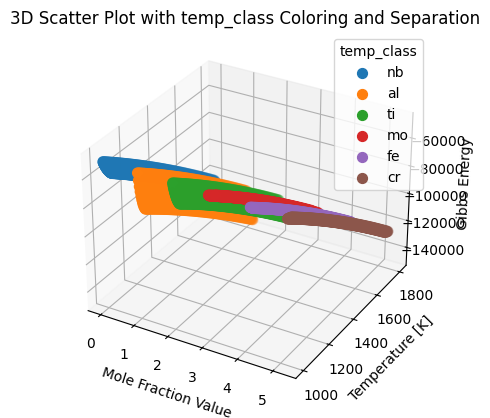

In [26]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import matplotlib.colors as mcolors

# Define colors for discrete values
color_dict = {'nb': 0, 'al': 1, 'ti': 2, 'mo': 3, 'fe': 4, 'cr': 5}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
offsets = np.array([0, 1, 2, 3, 4, 5])  # Offsets to separate classes

# Extract columns
mole_frac_value = full_d_list[:, 0]
temperature = full_d_list[:, 1]
gibbs_energy = full_d_list[:, 2]
temp_class_num = full_d_list[:, 3]

# Add slight noise for better separation
# noise_level = 0.01
# mole_frac_value += np.random.normal(0, noise_level, mole_frac_value.shape)
# temperature += np.random.normal(0, noise_level, temperature.shape)
# gibbs_energy += np.random.normal(0, noise_level, gibbs_energy.shape)

# Create a 3D scatter plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter plot with individual colors for each category
for temp_class, color in color_dict.items():
    mask = temp_class_num == color
    # Apply offset to avoid overlap
    offset = offsets[color]
    ax.scatter(mole_frac_value[mask] + offset, 
               temperature[mask], 
               gibbs_energy[mask], 
               color=colors[color], 
               label=temp_class, 
               s=50)

# Add legend
ax.legend(title='temp_class')

# Set labels
ax.set_xlabel('Mole Fraction Value')
ax.set_ylabel('Temperature [K]')
ax.set_zlabel('Gibbs Energy')
ax.set_title('3D Scatter Plot with temp_class Coloring and Separation')

# Show plot
plt.show()


In [29]:
mole_frac_value_standardized = full_d_list[:, 0]  # Standardized mass fraction
temperature_standardized = full_d_list[:, 1]      # Standardized temperature
gibbs_energy_standardized = full_d_list[:, 2]     # Standardized Gibbs energy
temp_class_num = full_d_list[:, 3].astype(int)    # Encoded temp_class number

In [30]:
mole_frac_value_standardized.shape

(8181,)

In [31]:
vars(scaler)

{'mean_': Mass_fraction_Nb       0.069307
 Mass_fraction_Al       0.015347
 Mass_fraction_Ti       0.028713
 Mass_fraction_Mo       0.044554
 Mass_fraction_Fe       0.195545
 Mass_fraction_Ni       0.530000
 Mass_fraction_Cr       0.182178
 Temperature_[K]     1400.000000
 dtype: float64,
 'scale_': Mass_fraction_Nb      0.050232
 Mass_fraction_Al      0.036215
 Mass_fraction_Ti      0.045786
 Mass_fraction_Mo      0.039615
 Mass_fraction_Fe      0.010552
 Mass_fraction_Ni      0.000000
 Mass_fraction_Cr      0.012154
 Temperature_[K]     233.809039
 dtype: float64}

In [32]:
df

,Gibbs_energy,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
0,-49238.12,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1000,nb
1,-50066.89,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1010,nb
2,-50898.83,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1020,nb
3,-51733.93,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1030,nb
4,-52572.17,0.00,0.005,0.01,0.03,0.195,0.53,0.18,1040,nb
...,...,...,...,...,...,...,...,...,...,...
8176,-121687.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1760,cr
8177,-122729.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1770,cr
8178,-123773.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1780,cr
8179,-124819.00,0.05,0.005,0.01,0.03,0.195,0.53,0.25,1790,cr


In [27]:
mole_frac_value_standardized = full_d_list[:, 0]  # Standardized mass fraction
temperature_standardized = full_d_list[:, 1]      # Standardized temperature
gibbs_energy_standardized = full_d_list[:, 2]     # Standardized Gibbs energy
temp_class_num = full_d_list[:, 3].astype(int)    # Encoded temp_class number

# Let's assume you've already fitted a scaler instance (as before)
# scaler = CustomStandardScaler()

# Assuming you have already fitted the scaler to the data before transforming:
# Re-transform Gibbs energy, mole fraction, and temperature to original scale
gibbs_energy_original = scaler.inverse_transform(gibbs_energy_standardized)
mole_frac_value_original = scaler.inverse_transform(mole_frac_value_standardized)
temperature_original = scaler.inverse_transform(temperature_standardized)

gibbs_energy_original = df['Gibbs_energy']
temperature_original = df['Temperature_[K]']

# Define colors and offsets for plotting
color_dict = {'nb': 0, 'al': 1, 'ti': 2, 'mo': 3, 'fe': 4, 'cr': 5}
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']
offsets = np.array([0, 1, 2, 3, 4, 5])  # Offsets to separate classes

# Create a new 3D scatter plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for temp_class, color in color_dict.items():
    mask = temp_class_num == color
    # Apply offset to avoid overlap
    offset = offsets[color]

    # Scatter the original data points
    ax.scatter(mole_frac_value_original[mask] + offset, 
               temperature_original[mask], 
               gibbs_energy_original[mask], 
               color=colors[color], 
               label=temp_class, 
               s=50)

    # Now evaluate and plot the equation predictions
    if temp_class == 'nb':
        predictions = medium_equations['nb'](gibbs_energy_standardized[mask], mole_frac_value_standardized[mask])
    elif temp_class == 'al':
        predictions = medium_equations['al'](gibbs_energy_standardized[mask], mole_frac_value_standardized[mask])
    elif temp_class == 'ti':
        predictions = medium_equations['ti'](gibbs_energy_standardized[mask], mole_frac_value_standardized[mask])
    elif temp_class == 'mo':
        predictions = medium_equations['mo'](gibbs_energy_standardized[mask], mole_frac_value_standardized[mask])
    elif temp_class == 'fe':
        predictions = medium_equations['fe'](gibbs_energy_standardized[mask], mole_frac_value_standardized[mask])
    elif temp_class == 'cr':
        predictions = medium_equations['cr'](gibbs_energy_standardized[mask], mole_frac_value_standardized[mask])
    
    # Inverse transform the predicted Gibbs energy
    predictions_original = scaler.inverse_transform(predictions)

    # Plot the predicted values on the same scatter plot
    ax.plot(mole_frac_value_original[mask] + offset, 
            temperature_original[mask], 
            predictions_original, 
            color=colors[color], 
            label=f'{temp_class}_fit', 
            linestyle='--')

# Add legend
ax.legend(title='temp_class')

# Set labels
ax.set_xlabel('Mole Fraction Value')
ax.set_ylabel('Temperature [K]')
ax.set_zlabel('Gibbs Energy')
ax.set_title('3D Scatter Plot with temp_class Coloring and Symbolic Regression Fits')

# Show plot
plt.show()

ValueError: operands could not be broadcast together with shapes (8181,) (8,) 

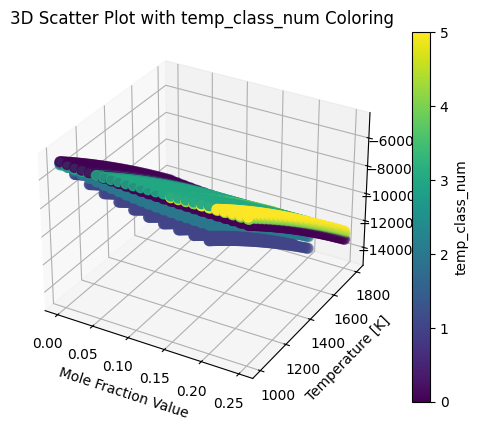

In [125]:

# Extract columns
mole_frac_value = full_d_list[:, 0]
temperature = full_d_list[:, 1]
gibbs_energy = full_d_list[:, 2]
temp_class_num = full_d_list[:, 3]

# Create a 3D scatter plot
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter plot
scatter = ax.scatter(mole_frac_value, temperature, gibbs_energy, c=temp_class_num, cmap='viridis', s=50)

# Add color bar
colorbar = plt.colorbar(scatter, ax=ax)
colorbar.set_label('temp_class_num')

# Set labels
ax.set_xlabel('Mole Fraction Value')
ax.set_ylabel('Temperature [K]')
ax.set_zlabel('Gibbs Energy')
ax.set_title('3D Scatter Plot with temp_class_num Coloring')

plt.show()

In [112]:
full_d_list

array([[ 0.000000e+00,  1.000000e+03, -4.923812e+04,  0.000000e+00],
       [ 0.000000e+00,  1.010000e+03, -5.006689e+04,  0.000000e+00],
       [ 0.000000e+00,  1.020000e+03, -5.089883e+04,  0.000000e+00],
       ...,
       [ 2.500000e-01,  1.780000e+03, -1.237730e+05,  5.000000e+00],
       [ 2.500000e-01,  1.790000e+03, -1.248190e+05,  5.000000e+00],
       [ 2.500000e-01,  1.800000e+03, -1.258680e+05,  5.000000e+00]])

In [105]:
min_gibbs_energy = np.min(z[:, 0])
max_gibbs_energy = np.max(z[:, 0])


p = figure(width=1000, height=1000, x_range=(0, 3), y_range=(0, 2))

levels = np.linspace(min_gibbs_energy, max_gibbs_energy, 20)
contour_renderer = p.contour(x, y, z, levels, fill_color=Sunset8, line_color="black")

colorbar = contour_renderer.construct_color_bar()
p.add_layout(colorbar, "right")

show(p)

In [78]:
import pandas as pd
from math import sqrt
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
from bokeh.palettes import Category20
from bokeh.transform import factor_cmap

# Load the data into a DataFrame
# data = pd.DataFrame({
#     'Gibbs_energy': [-49238.12, -50066.89, -50898.83, -51733.93],
#     'Mass_fraction_Nb': [0, 0, 0, 0],
#     'Mass_fraction_Al': [0.005, 0.005, 0.005, 0.005],
#     'Mass_fraction_Ti': [0.01, 0.01, 0.01, 0.01],
#     'Mass_fraction_Mo': [0.03, 0.03, 0.03, 0.03],
#     'Mass_fraction_Fe': [0.195, 0.195, 0.195, 0.195],
#     'Mass_fraction_Ni': [0.53, 0.53, 0.53, 0.53],
#     'Mass_fraction_Cr': [0.18, 0.18, 0.18, 0.18],
#     'Temperature_[K]': [1000, 1010, 1020, 1030],
#     'temp_class': ['nb', 'nb', 'nb', 'nb']
# })

# Data Preparation: Create a mapping for mass fractions and temp_class
df['Mass_fraction'] = df[['Mass_fraction_Nb', 'Mass_fraction_Al']].max(axis=1)
df['Class'] = df['temp_class']

# Output to notebook
output_notebook()

# Initialize a Bokeh figure
p = figure(width=800, height=400, title="Mass Fraction vs. Gibbs Energy",
           x_axis_label='Mass Fraction', y_axis_label='Gibbs Energy', tools="pan,box_zoom,reset")

# Define the color mapping for temp_class
class_labels = df['Class'].unique()
color_map = factor_cmap('Class', palette=Category20[len(class_labels)], factors=class_labels)

# Plot concentric circles for each class
for temp_class in class_labels:
    class_data = df[df['Class'] == temp_class]
    p.circle(class_data['Mass_fraction'], class_data['Gibbs_energy'],
             size=10, color=color_map, legend_label=temp_class, fill_alpha=0.6, line_color=None)

# Add legend and configure the plot
p.legend.title = "Temperature Class"
p.legend.location = "top_left"
p.title.text_font_size = '14pt'
p.xaxis.axis_label_text_font_size = '12pt'
p.yaxis.axis_label_text_font_size = '12pt'

# Show the plot
show(p)


Loading BokehJS ...

ValueError: failed to validate CategoricalColorMapper(id='p3599', ...).factors: expected an element of either Seq(String), Seq(Tuple(String, String)) or Seq(Tuple(String, String, String)), got array([4, 0, 5, 3, 2, 1], dtype=int8)

In [77]:
# Create unique identifiers for each combination of x and y
df['id'] = df.groupby(['Mass_fraction_Nb', 'Temperature_[K]']).ngroup()

# Extract x and y arrays
x = df[['Mass_fraction_Nb', 'Temperature_[K]']].values

# Extract z array, ensuring the same shape as x and y
z = df[['Gibbs_energy', 'id']].pivot(index='id', columns=['Mass_fraction_Nb', 'Temperature_[K]'], values='Gibbs_energy').values

# Ensure that x and y are in (n, 2) format
print("x array shape:", x.shape)  # Should be (n, 2)
print("y array shape:", y.shape)  # Should be (n, 2)
print("z array shape:", z.shape)  # Should be (n, 2)

# Verify data
print("x array:")
print(x)
print("\ny array:")
print(y)
print("\nz array:")
print(z)

KeyError: 'Mass_fraction_Nb'

In [69]:
from bokeh.plotting import figure, show
from bokeh.models import ColorBar, LinearColorMapper
from bokeh.transform import linear_cmap
import numpy as np
import pandas as pd
from bokeh.palettes import Viridis256
from bokeh.io import output_notebook
x_vals = x[:, 0]
y_vals = y[:, 0]
z_vals = z.transpose()

print(y_vals.shape, z_vals.shape)

output_notebook()
min_gibbs_energy = np.min(z[:, 0])
max_gibbs_energy = np.max(z[:, 0])

levels = np.linspace(min_gibbs_energy, max_gibbs_energy, 9)

p = figure(width=800, height=400, title="Contour Plot of Gibbs Energy",
           x_axis_label='Mass Fraction', y_axis_label='Temperature [K]')

# Prepare color mapper
mapper = LinearColorMapper(palette=Viridis256, low=min_gibbs_energy, high=max_gibbs_energy)

# Create a scatter plot
p.scatter(x_vals, y_vals, size=10, color=linear_cmap('z', Viridis256, min_gibbs_energy, max_gibbs_energy))

# Create contours
contour_renderer = p.contour(x_vals, y_vals, z_vals, levels, fill_color='Viridis256', line_color="black")

# Add color bar
color_bar = ColorBar(color_mapper=mapper, width=8, location=(0,0))
p.add_layout(color_bar, 'right')

# Show the plot
show(p)

(8181,) (2, 8181)


Loading BokehJS ...

TypeError: Length of y (8181) must match number of rows in z (2)

In [55]:
gibbs_energy_values = z[:, 0]  # Gibbs energy is in the first column

# Compute minimum and maximum values
min_gibbs_energy = np.min(gibbs_energy_values)
max_gibbs_energy = np.max(gibbs_energy_values)


In [50]:
min_gibbs_energy

-146406.0

In [56]:
print(x.shape, y.shape, z.shape)
p = figure(width=550, height=300, x_range=(0, 3), y_range=(0, 2))

levels = np.linspace(min_gibbs_energy, max_gibbs_energy, 9)
contour_renderer = p.contour(x, y, z, levels, fill_color=Sunset8, line_color="black")

colorbar = contour_renderer.construct_color_bar()
p.add_layout(colorbar, "right")

show(p)

(8181, 2) (8181, 2) (8181, 2)


In [39]:
import pandas as pd
import numpy as np
from bokeh.plotting import figure, show
from bokeh.io import output_notebook
from bokeh.palettes import Sunset8
from bokeh.models import ColorBar, LinearColorMapper
from bokeh.transform import linear_cmap
from bokeh.layouts import column
from bokeh.palettes import Viridis256

# Load the data into a DataFrame
data = pd.DataFrame({
    'Gibbs_energy': [-49238.12, -50066.89, -50898.83, -51733.93],
    'Mass_fraction_Nb': [0, 0, 0, 0],
    'Mass_fraction_Al': [0.005, 0.005, 0.005, 0.005],
    'Mass_fraction_Ti': [0.01, 0.01, 0.01, 0.01],
    'Mass_fraction_Mo': [0.03, 0.03, 0.03, 0.03],
    'Mass_fraction_Fe': [0.195, 0.195, 0.195, 0.195],
    'Mass_fraction_Ni': [0.53, 0.53, 0.53, 0.53],
    'Mass_fraction_Cr': [0.18, 0.18, 0.18, 0.18],
    'Temperature_[K]': [1000, 1010, 1020, 1030],
    'temp_class': ['nb', 'nb', 'nb', 'nb']
})

# Data Preparation
data['Mass_fraction'] = data[['Mass_fraction_Nb', 'Mass_fraction_Al']].max(axis=1)
data['Class'] = data['temp_class']
data['x'] = data['Mass_fraction']
data['y'] = data['Gibbs_energy']

# Create mesh grid for contour plotting
x_range = np.linspace(data['x'].min() - 0.01, data['x'].max() + 0.01, 100)
y_range = np.linspace(data['y'].min() - 10000, data['y'].max() + 10000, 100)
X, Y = np.meshgrid(x_range, y_range)

# Interpolate Gibbs energy data on the grid
from scipy.interpolate import griddata
Z = griddata((data['x'], data['y']), data['Gibbs_energy'], (X, Y), method='linear')

# Initialize a Bokeh figure
output_notebook()
p = figure(width=800, height=400, title="Contour Plot of Gibbs Energy",
           x_axis_label='Mass Fraction', y_axis_label='Gibbs Energy', tools="pan,box_zoom,reset")

# Create contour plot
contour_renderer = p.contour(X, Y, Z, levels=10, fill_color=linear_cmap('value', Viridis256, low=Z.min(), high=Z.max()), line_color="black")

# Add color bar
color_mapper = LinearColorMapper(palette=Viridis256, low=Z.min(), high=Z.max())
colorbar = ColorBar(color_mapper=color_mapper, width=8, location=(0,0))
p.add_layout(colorbar, 'right')

# Show plot
show(p)


QhullError: QH6013 qhull input error: input is less than 3-dimensional since all points have the same x coordinate 0.005

While executing:  | qhull d Q12 Qbb Qc Qt Qz
Options selected for Qhull 2019.1.r 2019/06/21:
  run-id 1186717510  delaunay  Q12-allow-wide  Qbbound-last  Qcoplanar-keep
  Qtriangulate  Qz-infinity-point  _pre-merge  _zero-centrum  Qinterior-keep
  Pgood  _max-width 2.5e+03  Error-roundoff 7.2e-11  _one-merge 5e-10
  Visible-distance 1.4e-10  U-max-coplanar 1.4e-10  Width-outside 2.9e-10
  _wide-facet 8.6e-10  _maxoutside 5.7e-10


In [29]:
df.head()

,Gibbs_energy,Mass_fraction_Nb,Mass_fraction_Al,Mass_fraction_Ti,Mass_fraction_Mo,Mass_fraction_Fe,Mass_fraction_Ni,Mass_fraction_Cr,Temperature_[K],temp_class
0,-49238.12,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1000,nb
1,-50066.89,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1010,nb
2,-50898.83,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1020,nb
3,-51733.93,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1030,nb
4,-52572.17,0.0,0.005,0.01,0.03,0.195,0.53,0.18,1040,nb
